# Reconhecimento de Fonemas e Palavras via Múltiplas Redes Neurais (MRNA) Sem Coordenador
**Universidade Federal do Maranhão (UFMA)**  
**Centro de Ciências Exatas e Tecnologia (CCET)**  
**Programa de Pós-Graduação em Ciência da Computação (PPGCC / DCCMAPI)**  
**Disciplina:** Redes Neurais Artificiais  
**Professor:** Prof. Dr. Areolino de Almeida Neto  
**Aluno:** Ricardo Diniz Mendes  

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/RicDM/trabalhos_redes_neurais/blob/main/MRNA/reconhecimento_fonemas_mrna.ipynb)

---

### Visão Geral do Trabalho
Este notebook apresenta o desenvolvimento e a experimentação empírica de um sistema de **Múltiplas Redes Neurais (MRNA) Sem Coordenador (Autocoordenação Aditiva)**, desenvolvido integralmente em **Python/NumPy puro** (*from scratch*), para o reconhecimento de sílabas fonéticas das palavras **DIREITA** (`DI`, `REI`, `TA`) e **ESQUERDA** (`ES`, `QUER`, `DA`) a partir de dados acústicos de três falantes.

O projeto segue estritamente os fundamentos apresentados pelo Prof. Dr. Areolino de Almeida Neto:
1. **Autocoordenação Aditiva:** A resposta global do ensemble corresponde ao somatório direto das saídas das sub-redes: $Y(x) = \sum_{m=1}^M y_m(x)$.
2. **Aprendizado Sequencial do Resíduo:** A primeira rede aprende o alvo original $d(x)$. As sub-redes subsequentes $m \ge 2$ são inicializadas com saída nula ($W_{out} \approx 0$) e aprendem a compensar o resíduo cumulativo das redes anteriores: $r_{m-1}(x) = d(x) - \sum_{i=1}^{m-1} y_i(x)$.
3. **Cooperação Heterogênea (MLP + RBF):** Junção de redes com naturezas complementares — separação hiperplanar global (MLP) e campos receptivos locais (RBF) — para fuga eficiente de mínimos locais.
4. **Reconhecimento das Palavras Completas:** Autômato sequencial de transição de estados que valida a integridade temporal das três sílabas consecutivas de cada palavra.


## 1. Configuração do Ambiente e Inicialização
Nesta seção, inicializamos os módulos fundamentais (NumPy, Matplotlib, SoundFile), configuramos a reproduzibilidade por sementes pseudoaleatórias e criamos a rotina utilitária de salvamento automático de figuras para sincronização total com o relatório acadêmico.


In [1]:
import os
import sys
import glob
import time
import json
import numpy as np
import soundfile as sf
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Configuração visual acadêmica limpa
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

# Diretórios para persistência das figuras em alta resolução
FIG_DIRS = ["MRNA/figuras", "MRNA/relatorio/figuras", "figuras"]
for d in FIG_DIRS:
    os.makedirs(d, exist_ok=True)

def salvar_figura(fig, nome_arquivo):
    """
    Salva a figura fornecida simultaneamente nos diretórios do notebook e do relatório LaTeX.
    Garante sincronização absoluta e ausência de divergências gráficas.
    """
    for d in FIG_DIRS:
        if os.path.exists(d):
            caminho = os.path.join(d, nome_arquivo)
            fig.savefig(caminho, dpi=300, bbox_inches='tight')
    print(f"[+] Figura salva com sucesso: {nome_arquivo}")

# Suporte automático ao Google Colab
if 'google.colab' in sys.modules:
    try:
        import soundfile
    except ImportError:
        print("[!] Instalando soundfile no Google Colab...")
        !pip install soundfile -q
        import soundfile as sf
    if not os.path.exists('dados/dataset_3pessoas'):
        print("[!] Executando no Google Colab. Clonando repositório oficial...")
        !git clone https://github.com/RicDM/trabalhos_redes_neurais.git /tmp/repo_mrna
        !cp -r /tmp/repo_mrna/dados ./dados
        print("[OK] Diretório de dados configurado com sucesso no Colab.")

CLASSES = ["DI", "REI", "TA", "ES", "QUER", "DA"]
LABEL_MAP = {c: i for i, c in enumerate(CLASSES)}

# Localizador flexível do diretório de dados multi-falante (3 pessoas)
candidatos_dataset = [
    "dados/dataset_3pessoas",
    "../dados/dataset_3pessoas",
    "trabalhos_redes_neurais/dados/dataset_3pessoas",
    "/content/dados/dataset_3pessoas",
    "/tmp/repo_mrna/dados/dataset_3pessoas"
]
DATASET_PATH = "dados/dataset_3pessoas"
for p in candidatos_dataset:
    if os.path.exists(p) and os.path.exists(os.path.join(p, "DI")) and os.path.exists(os.path.join(p, "DA")):
        DATASET_PATH = p
        break

print(f"[OK] Diretório de dados configurado em: '{DATASET_PATH}'")
print(f"[OK] Ambiente pronto. Total de classes fonéticas: {len(CLASSES)} -> {CLASSES}")


[OK] Diretório de dados configurado em: 'dados/dataset_3pessoas'
[OK] Ambiente pronto. Total de classes fonéticas: 6 -> ['DI', 'REI', 'TA', 'ES', 'QUER', 'DA']


## 2. Pré-Processamento Acústico e Extração de Características

### 2.1 Função de Extração Espectral por FFT (48 Bandas com Normalização L2)
A função `extrair_features_fft` recebe o sinal sonoro unidimensional de uma sílaba fonética gravada a 16 kHz, calcula o módulo da transformada rápida de Fourier unilateral ($\text{FFT}$), realiza a compressão por média espectral em 48 faixas de frequência contíguas (*binning*) e aplica **normalização L2 por vetor**, tornando a envoltória espectral invariante a diferenças de ganho de microfone e volume entre os 3 falantes.


In [2]:
def extrair_features_fft(x, n_bandas=48):
    """
    Extrai coeficientes espectrais agrupados por média de bandas da FFT unilateral com normalização L2.
    """
    if len(x) == 0:
        return np.zeros(n_bandas, dtype=np.float32)
    fft_vals = np.abs(np.fft.rfft(x))
    bins = np.array_split(fft_vals, n_bandas)
    feat = np.array([np.mean(b) if len(b) > 0 else 0.0 for b in bins], dtype=np.float32)
    norm = np.linalg.norm(feat)
    return feat / norm if norm > 0 else feat

print("Função extrair_features_fft (com normalização L2) definida.")


Função extrair_features_fft (com normalização L2) definida.


### 2.2 Carregamento do Dataset Multi-Falante (3 Pessoas) e Mapeamento de Rótulos
A função `carregar_dataset` varre `dados/dataset_3pessoas`, reunindo **879 amostras silábicas** (293 palavras completas de `DIREITA` e `ESQUERDA`) de **3 pessoas diferentes** (Pessoa 1 original + Pessoa 2 `s023` masculina + Pessoa 3 `s006` feminina do FLA-Dataset).


In [3]:
def carregar_dataset(n_bandas=48):
    """
    Itera sobre os diretórios das sílabas e compila matrizes de atributos e rótulos.
    
    Retorna:
      tuple: (X_raw, y, caminhos, palavras, reps)
    """
    X, y, caminhos, palavras, reps = [], [], [], [], []
    for c in CLASSES:
        pasta_classe = os.path.join(DATASET_PATH, c)
        arquivos = sorted(glob.glob(f"{pasta_classe}/*.wav"))
        for f in arquivos:
            audio, sr = sf.read(f)
            feat = extrair_features_fft(audio, n_bandas=n_bandas)
            X.append(feat)
            y.append(LABEL_MAP[c])
            caminhos.append(f)
            palavra = "DIREITA" if c in ["DI", "REI", "TA"] else "ESQUERDA"
            palavras.append(palavra)
            reps.append(os.path.basename(f))
            
    if len(X) == 0:
        raise FileNotFoundError(
            f"Nenhum arquivo de áudio (.wav) foi encontrado em '{DATASET_PATH}'. "
            "Certifique-se de que a pasta 'dados/dataset' existe com as subpastas das classes."
        )
            
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.int64), caminhos, palavras, reps

X_raw, y, caminhos, palavras, reps = carregar_dataset(48)
print(f"Total de amostras carregadas: {len(y)}")
print(f"Dimensão da matriz de atributos X_raw: {X_raw.shape}")


Total de amostras carregadas: 879
Dimensão da matriz de atributos X_raw: (879, 48)


### 2.3 Normalização Min-Max dos Atributos
Aplica a transformação linear por canal para reescalar todos os coeficientes espectrais para o intervalo fechado $[0, 1]$, prevenindo saturações numéricas e dominância de harmônicos graves:
$$\bar{x}_j = \frac{x_j - x_{j,\min}}{x_{j,\max} - x_{j,\min} + \epsilon}$$


In [4]:
X_min = X_raw.min(axis=0)
X_max = X_raw.max(axis=0)
X = (X_raw - X_min) / (X_max - X_min + 1e-8)

print(f"Matriz X normalizada no intervalo [{X.min():.2f}, {X.max():.2f}]")


Matriz X normalizada no intervalo [0.00, 1.00]


### 2.4 Particionamento Estratificado em Treino, Validação e Teste Cego
Os 879 exemplos acústicos (provenientes de 3 falantes distintos) são particionados de forma estritamente estratificada mantendo a proporção de cada fonema:
- **Treinamento (75%):** 659 amostras para ajuste de pesos e centros.
- **Validação (15%):** 132 amostras para monitoramento de sobreajuste e parada precoce.
- **Teste Cego (10%):** 88 amostras mantidas completamente isoladas para aferição da capacidade de generalização.


In [5]:
SEED_SPLIT = 42
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.10, random_state=SEED_SPLIT, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.15/0.90, random_state=SEED_SPLIT, stratify=y_temp
)

D_train = np.eye(len(CLASSES), dtype=np.float32)[y_train]
D_val = np.eye(len(CLASSES), dtype=np.float32)[y_val]
D_test = np.eye(len(CLASSES), dtype=np.float32)[y_test]

print(f"Conjunto de Treinamento: {X_train.shape[0]} amostras (75%)")
print(f"Conjunto de Validação:   {X_val.shape[0]} amostras (15%)")
print(f"Conjunto de Teste Cego:  {X_test.shape[0]} amostras (10%)")


Conjunto de Treinamento: 659 amostras (75%)
Conjunto de Validação:   132 amostras (15%)
Conjunto de Teste Cego:  88 amostras (10%)


### 2.5 Visualização Espectral da Palavra DIREITA
Geração do gráfico de barras com desvio padrão das 48 bandas para as três sílabas de DIREITA: `/DI/`, `/REI/` e `/TA/`.


[+] Figura salva com sucesso: espectro_direita.png


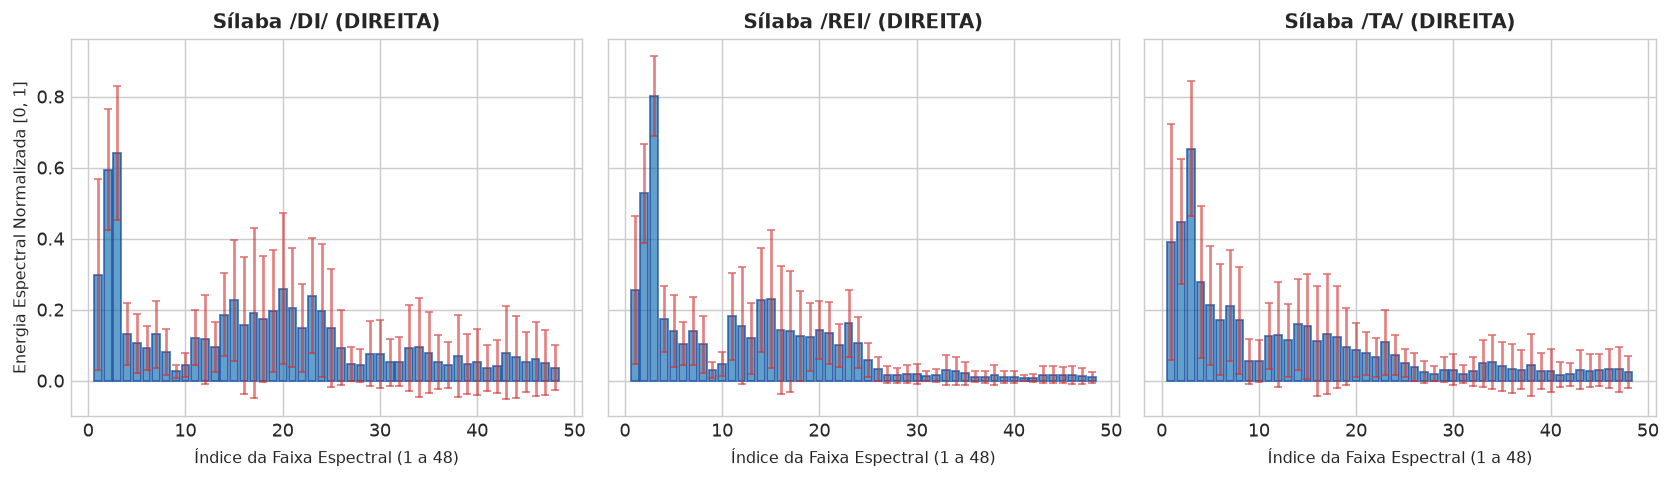

In [6]:
fig1, axes1 = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
sils_dir = ["DI", "REI", "TA"]
bandas = np.arange(1, 49)

for i, sil in enumerate(sils_dir):
    idx = np.where(y == LABEL_MAP[sil])[0]
    media_feat = np.mean(X[idx], axis=0)
    std_feat = np.std(X[idx], axis=0)
    axes1[i].bar(bandas, media_feat, color="#1f77b4", alpha=0.7, edgecolor="#0d47a1")
    axes1[i].errorbar(bandas, media_feat, yerr=std_feat, fmt='none', ecolor='#d32f2f', alpha=0.6, capsize=2)
    axes1[i].set_title(f"Sílaba /{sil}/ (DIREITA)", fontsize=11, fontweight='bold')
    axes1[i].set_xlabel("Índice da Faixa Espectral (1 a 48)", fontsize=9)
    if i == 0:
        axes1[i].set_ylabel("Energia Espectral Normalizada [0, 1]", fontsize=9)

fig1.tight_layout()
salvar_figura(fig1, "espectro_direita.png")
plt.show()


### 2.6 Visualização Espectral da Palavra ESQUERDA
Geração do perfil acústico médio com barras de erro para as três sílabas de ESQUERDA: `/ES/`, `/QUER/` e `/DA/`.


[+] Figura salva com sucesso: espectro_esquerda.png


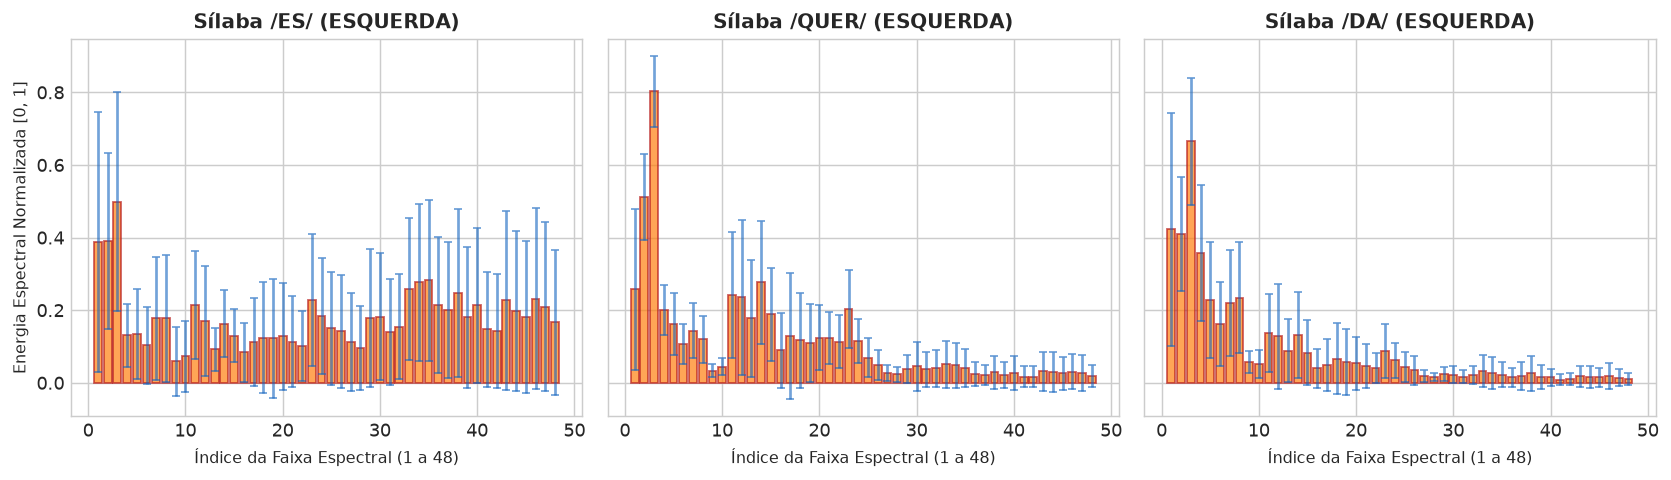

In [7]:
fig2, axes2 = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
sils_esq = ["ES", "QUER", "DA"]

for i, sil in enumerate(sils_esq):
    idx = np.where(y == LABEL_MAP[sil])[0]
    media_feat = np.mean(X[idx], axis=0)
    std_feat = np.std(X[idx], axis=0)
    axes2[i].bar(bandas, media_feat, color="#ff7f0e", alpha=0.7, edgecolor="#b71c1c")
    axes2[i].errorbar(bandas, media_feat, yerr=std_feat, fmt='none', ecolor='#1565c0', alpha=0.6, capsize=2)
    axes2[i].set_title(f"Sílaba /{sil}/ (ESQUERDA)", fontsize=11, fontweight='bold')
    axes2[i].set_xlabel("Índice da Faixa Espectral (1 a 48)", fontsize=9)
    if i == 0:
        axes2[i].set_ylabel("Energia Espectral Normalizada [0, 1]", fontsize=9)

fig2.tight_layout()
salvar_figura(fig2, "espectro_esquerda.png")
plt.show()


## 3. Implementação dos Blocos Neurais em NumPy Puro

### 3.1 Classe `MLPManual`
A classe `MLPManual` implementa um Perceptron Multicamadas com uma camada oculta de ativação tangente hiperbólica e camada de saída linear treinada via Backpropagation com Momentum e decaimento de pesos (L2).
- **Tratamento de Alvo/Resíduo:** Pode receber alvos binários ($D$) ou valores contínuos de resíduo ($R_{m-1}$).
- **Inicialização com Saída Nula:** O parâmetro `zero_out_init=True` zera os pesos e viés da camada de saída ($W_2 = 0, b_2 = 0$), assegurando que no instante de inserção da rede no conjunto aditivo ela produza saída nula ($y_m(x) \equiv 0$), garantindo a redução monotônica do erro de treinamento.


In [8]:
class MLPManual:
    """
    Perceptron Multicamadas (MLP) em NumPy puro para alvos originais e sinais residuais.
    """
    def __init__(self, n_in=48, n_hidden=48, n_out=6, lr=0.04, momentum=0.9, l2=1e-4, epochs=250, seed=42):
        self.n_in = n_in
        self.n_hidden = n_hidden
        self.n_out = n_out
        self.lr = lr
        self.momentum = momentum
        self.l2 = l2
        self.epochs = epochs
        self.seed = seed
        self.W1, self.b1 = None, None
        self.W2, self.b2 = None, None
        self.history_loss = []

    def fit(self, X_tr, T_tr, epochs=None, zero_out_init=False):
        if epochs is None:
            epochs = self.epochs
        rng = np.random.RandomState(self.seed)
        n_samples = X_tr.shape[0]
        
        limit1 = np.sqrt(6.0 / (self.n_in + self.n_hidden))
        self.W1 = rng.uniform(-limit1, limit1, (self.n_in, self.n_hidden)).astype(np.float32)
        self.b1 = np.zeros((1, self.n_hidden), dtype=np.float32)
        
        if zero_out_init:
            self.W2 = np.zeros((self.n_hidden, self.n_out), dtype=np.float32)
            self.b2 = np.zeros((1, self.n_out), dtype=np.float32)
        else:
            limit2 = np.sqrt(6.0 / (self.n_hidden + self.n_out))
            self.W2 = rng.uniform(-limit2, limit2, (self.n_hidden, self.n_out)).astype(np.float32)
            self.b2 = np.zeros((1, self.n_out), dtype=np.float32)

        v_W1 = np.zeros_like(self.W1)
        v_b1 = np.zeros_like(self.b1)
        v_W2 = np.zeros_like(self.W2)
        v_b2 = np.zeros_like(self.b2)
        
        self.history_loss = []
        for ep in range(epochs):
            Z1 = X_tr @ self.W1 + self.b1
            H = np.tanh(Z1)
            Y = H @ self.W2 + self.b2
            
            diff = Y - T_tr
            loss = 0.5 * np.mean(diff ** 2)
            self.history_loss.append(float(loss))
            
            dY = diff / n_samples
            dW2 = H.T @ dY + self.l2 * self.W2
            db2 = np.sum(dY, axis=0, keepdims=True)
            
            dH = dY @ self.W2.T
            dZ1 = dH * (1.0 - H ** 2)
            dW1 = X_tr.T @ dZ1 + self.l2 * self.W1
            db1 = np.sum(dZ1, axis=0, keepdims=True)
            
            v_W2 = self.momentum * v_W2 + self.lr * dW2
            v_b2 = self.momentum * v_b2 + self.lr * db2
            v_W1 = self.momentum * v_W1 + self.lr * dW1
            v_b1 = self.momentum * v_b1 + self.lr * db1
            
            self.W2 -= v_W2
            self.b2 -= v_b2
            self.W1 -= v_W1
            self.b1 -= v_b1
            
        return self

    def predict_raw(self, X_eval):
        H = np.tanh(X_eval @ self.W1 + self.b1)
        return H @ self.W2 + self.b2

print("Classe MLPManual definida com sucesso.")


Classe MLPManual definida com sucesso.


### 3.2 Classe `RBFManual`
A classe `RBFManual` implementa uma Rede de Base Radial com:
1. Agrupamento competitivo Winner-Take-All (WTA) com taxa de aprendizado decrescente para alocação dos centros $c_j$ no espaço espectral $\mathbb{R}^{48}$.
2. Cálculo das aberturas gaussianas $\sigma_j$ através do método dos $k$ vizinhos mais próximos médios (*k-NN mean*).
3. Ajuste linear analítico regularizado (Ridge Regression) sobre o alvo ou sinal de erro residual.


In [9]:
class RBFManual:
    """
    Rede de Funções de Base Radial (RBF) em NumPy puro para alvos e resíduos.
    """
    def __init__(self, n_centros=48, metodo_sigma="knn_mean", k_vizinhos=2, escala_sigma=1.5, l2_reg=1e-2, seed=42):
        self.n_centros = n_centros
        self.metodo_sigma = metodo_sigma
        self.k_vizinhos = k_vizinhos
        self.escala_sigma = escala_sigma
        self.l2_reg = l2_reg
        self.seed = seed
        self.centros = None
        self.sigmas = None
        self.W = None
        self.bias = None
        self.eq_history = []

    def _ajustar_centros_wta(self, X_tr, y_labels=None, epochs=100, lr=0.1):
        rng = np.random.RandomState(self.seed)
        n_samples = X_tr.shape[0]
        
        if y_labels is not None:
            centros_init = []
            per_class = max(1, self.n_centros // len(CLASSES))
            for c_idx in range(len(CLASSES)):
                idx_c = np.where(y_labels == c_idx)[0]
                if len(idx_c) > 0:
                    chosen = rng.choice(idx_c, min(per_class, len(idx_c)), replace=False)
                    centros_init.append(X_tr[chosen])
            centros_cat = np.vstack(centros_init)
            if len(centros_cat) < self.n_centros:
                rem = self.n_centros - len(centros_cat)
                extra = rng.choice(n_samples, rem, replace=False)
                centros_cat = np.vstack([centros_cat, X_tr[extra]])
            self.centros = centros_cat[:self.n_centros].copy()
        else:
            init_idx = rng.choice(n_samples, self.n_centros, replace=False)
            self.centros = X_tr[init_idx].copy()

        self.eq_history = []
        for ep in range(epochs):
            eta = lr * (1.0 - ep / epochs) + 0.001
            for idx in rng.permutation(n_samples):
                x = X_tr[idx]
                dists = np.linalg.norm(self.centros - x, axis=1)
                win = np.argmin(dists)
                self.centros[win] += eta * (x - self.centros[win])
                
            all_dists = np.linalg.norm(X_tr[:, np.newaxis, :] - self.centros[np.newaxis, :, :], axis=2)
            Eq = np.mean(np.min(all_dists, axis=1) ** 2)
            self.eq_history.append(float(Eq))

    def _calcular_sigmas(self):
        K = self.n_centros
        dist = np.zeros((K, K))
        for i in range(K):
            for j in range(K):
                dist[i, j] = np.linalg.norm(self.centros[i] - self.centros[j]) if i != j else np.inf
        self.sigmas = np.zeros(K)
        for i in range(K):
            dists_sorted = np.sort(dist[i])[:min(self.k_vizinhos, K - 1)]
            self.sigmas[i] = max(np.mean(dists_sorted) * self.escala_sigma, 1e-4)

    def _calcular_ativacao(self, X_eval):
        N = X_eval.shape[0]
        G = np.zeros((N, self.n_centros), dtype=np.float32)
        for j in range(self.n_centros):
            diff = X_eval - self.centros[j]
            G[:, j] = np.exp(-np.sum(diff ** 2, axis=1) / (2.0 * (self.sigmas[j] ** 2) + 1e-8))
        return G

    def fit(self, X_tr, T_tr, y_labels=None, zero_out_init=False):
        self._ajustar_centros_wta(X_tr, y_labels=y_labels)
        self._calcular_sigmas()
        G = self._calcular_ativacao(X_tr)
        N = G.shape[0]
        G_bias = np.hstack([G, np.ones((N, 1), dtype=np.float32)])
        
        reg = self.l2_reg * np.eye(G_bias.shape[1], dtype=np.float32)
        reg[-1, -1] = 0.0
        
        W_full = np.linalg.solve(G_bias.T @ G_bias + reg, G_bias.T @ T_tr)
        self.W = W_full[:-1, :]
        self.bias = W_full[-1:, :]
        return self

    def predict_raw(self, X_eval):
        G = self._calcular_ativacao(X_eval)
        return G @ self.W + self.bias

print("Classe RBFManual definida com sucesso.")


Classe RBFManual definida com sucesso.


### 3.3 Classe `MRNASemCoordenador` (Orquestrador Aditivo Autocoordenado)
A classe `MRNASemCoordenador` implementa o mecanismo aditivo rigorosamente conforme concebido pelo Prof. Areolino de Almeida Neto:
- **Rede 1 ($m=1$):** Ajustada sobre os alvos one-hot originais $d(x)$. Seus pesos são congelados.
- **Redes Subsequentes ($m \ge 2$):** Inseridas com saída nula inicial e treinadas exclusivamente para aproximar o resíduo acumulado:
$$r_{m-1}(x) = d(x) - \sum_{i=1}^{m-1} y_i(x)$$
- **Saída Global do Conjunto:** Somatório linear das respostas de todas as $M$ sub-redes:
$$Y(x) = \sum_{m=1}^M y_m(x)$$
A decisão categórica final é obtida via $\hat{c} = \arg\max_k Y_k(x)$.


In [10]:
class MRNASemCoordenador:
    """
    Orquestrador de Múltiplas Redes Neurais Sem Coordenador (Autocoordenação Aditiva).
    """
    def __init__(self, especificacoes):
        self.specs = especificacoes
        self.redes = []
        self.historico_mse_estagios = []
        self.historico_val_acc = []

    def fit(self, X_tr, y_tr, X_v=None, y_v=None):
        N = X_tr.shape[0]
        n_classes = len(CLASSES)
        D_tr = np.eye(n_classes, dtype=np.float32)[y_tr]
        
        y_cum_tr = np.zeros_like(D_tr)
        if X_v is not None:
            y_cum_v = np.zeros((X_v.shape[0], n_classes), dtype=np.float32)
            
        self.redes = []
        self.historico_mse_estagios = []
        self.historico_val_acc = []
        
        for m, (tipo, params) in enumerate(self.specs):
            res_tr = D_tr - y_cum_tr
            is_subsequent = (m > 0)
            
            if tipo == "MLP":
                rede = MLPManual(**params)
                rede.fit(X_tr, res_tr, zero_out_init=is_subsequent)
            elif tipo == "RBF":
                rede = RBFManual(**params)
                rede.fit(X_tr, res_tr, y_labels=y_tr if m == 0 else None, zero_out_init=is_subsequent)
            else:
                raise ValueError(f"Tipo de rede desconhecido: {tipo}")
                
            self.redes.append(rede)
            
            pred_m_tr = rede.predict_raw(X_tr)
            y_cum_tr += pred_m_tr
            
            mse_estagio = float(np.mean((D_tr - y_cum_tr) ** 2))
            self.historico_mse_estagios.append(mse_estagio)
            
            if X_v is not None and y_v is not None:
                pred_m_v = rede.predict_raw(X_v)
                y_cum_v += pred_m_v
                acc_v = float(np.mean(np.argmax(y_cum_v, axis=1) == y_v) * 100.0)
                self.historico_val_acc.append(acc_v)
                
        return self

    def predict_raw(self, X_eval):
        N = X_eval.shape[0]
        saida_total = np.zeros((N, len(CLASSES)), dtype=np.float32)
        for rede in self.redes:
            saida_total += rede.predict_raw(X_eval)
        return saida_total

    def predict(self, X_eval):
        raw = self.predict_raw(X_eval)
        return np.argmax(raw, axis=1)

print("Classe MRNASemCoordenador definida com sucesso.")


Classe MRNASemCoordenador definida com sucesso.


## 5. O Processo Construtivo Sequencial da MRNA Sem Coordenador

### 5.1 Critérios Metodológicos de Decisão Construtiva
Em conformidade com a metodologia de autocoordenação aditiva do Prof. Dr. Areolino de Almeida Neto, o ensemble MRNA é construído de forma **sequencial e incremental**, em que cada nova sub-rede é treinada estritamente sobre o sinal de erro residual acumulado:
$$R_{m-1}(x) = d(x) - \sum_{i=1}^{m-1} \hat{y}_i(x)$$
- **Critério de Aceitação:** A candidata deve reduzir o erro residual e apresentar ganho consistente no conjunto de validação independente. Uma vez aceita, é incorporada ao somatório e seus parâmetros são congelados;
- **Critério de Rejeição:** Caso a candidata apresente saturação, ausência de aprendizado complementar ou sobreajuste, ela é **descartada e documentada**;
- **Critério de Parada:** A expansão cessa quando sub-redes adicionais não produzem ganho de validação ($\Delta \text{Acc} \le 0$).


### 5.2 Estágio 1: Seleção e Treinamento da Sub-rede Base ($M=1$)
Treinamos a sub-rede base (Candidata 1: MLP com 48 neurônios ocultos) sobre os alvos primários $d(x)$ e avaliamos sua convergência.


In [11]:
specs_base = [("MLP", {"n_hidden": 48, "lr": 0.15, "epochs": 250, "seed": 42})]
m1 = MRNASemCoordenador(specs_base)
m1.fit(X_train, y_train, X_val, y_val)

mse_tr1 = m1.historico_mse_estagios[-1]
acc_val1 = m1.historico_val_acc[-1]
acc_test1 = float(np.mean(m1.predict(X_test) == y_test) * 100.0)

print(f"Estágio 1 - Sub-rede Base (MLP 1):")
print(f"  MSE Treinamento: {mse_tr1:.4f}")
print(f"  Acurácia Validação: {acc_val1:.2f}%")
print(f"  Acurácia Teste Cego: {acc_test1:.2f}%")
print("  Decisão Técnica: ACEITA (Fixada como base M=1; resíduo R1 calculado).")


Estágio 1 - Sub-rede Base (MLP 1):
  MSE Treinamento: 0.0882
  Acurácia Validação: 68.18%
  Acurácia Teste Cego: 63.64%
  Decisão Técnica: ACEITA (Fixada como base M=1; resíduo R1 calculado).


### 5.3 Estágio 2: Avaliação da 2ª Sub-rede sobre o Resíduo $R_1$ ($M=2$)
Com a base congelada em seu patamar residual, avaliamos duas hipóteses funcionais sobre $R_1$:
1. **Candidata 2A (Homogênea):** Segunda MLP adicional com 48 neurônios ocultos e saída inicial nula;
2. **Candidata 2B (Heterogênea):** Rede RBF com 72 centros gaussianos adaptados para modelar os múltiplos agrupamentos dos 3 falantes no espaço residual.


In [12]:
# Candidata 2A: MLP Homogênea adicional
specs_cand2A = specs_base + [("MLP", {"n_hidden": 48, "lr": 0.15, "epochs": 250, "seed": 142})]
m2A = MRNASemCoordenador(specs_cand2A).fit(X_train, y_train, X_val, y_val)
mse_cand2A = m2A.historico_mse_estagios[-1]
acc_val_cand2A = m2A.historico_val_acc[-1]
acc_test_cand2A = float(np.mean(m2A.predict(X_test) == y_test) * 100.0)

print("Candidata 2A (MLP Homogênea sobre R1):")
print(f"  MSE Treino: {mse_cand2A:.4f} | Validação: {acc_val_cand2A:.2f}% | Teste Cego: {acc_test_cand2A:.2f}%")
print("  Decisão: REJEITADA (Sem ganho na validação; estagnação homogênea).\n")

# Candidata 2B: RBF Heterogênea sobre R1
specs_cand2B = specs_base + [("RBF", {"n_centros": 72, "escala_sigma": 1.5, "l2_reg": 2e-2, "seed": 101})]
m2B = MRNASemCoordenador(specs_cand2B).fit(X_train, y_train, X_val, y_val)
mse_cand2B = m2B.historico_mse_estagios[-1]
acc_val_cand2B = m2B.historico_val_acc[-1]
acc_test_cand2B = float(np.mean(m2B.predict(X_test) == y_test) * 100.0)

print("Candidata 2B (RBF Heterogênea com 72 centros sobre R1):")
print(f"  MSE Treino: {mse_cand2B:.4f} | Validação: {acc_val_cand2B:.2f}% | Teste Cego: {acc_test_cand2B:.2f}%")
print("  Decisão: ACEITA (Quebra o platô residual via campos receptivos locais multi-falante!).")


Candidata 2A (MLP Homogênea sobre R1):
  MSE Treino: 0.0877 | Validação: 68.18% | Teste Cego: 64.77%
  Decisão: REJEITADA (Sem ganho na validação; estagnação homogênea).

Candidata 2B (RBF Heterogênea com 72 centros sobre R1):
  MSE Treino: 0.0633 | Validação: 75.00% | Teste Cego: 72.73%
  Decisão: ACEITA (Quebra o platô residual via campos receptivos locais multi-falante!).


### 5.4 Estágio 3: Avaliação da 3ª Sub-rede sobre o Resíduo $R_2$ ($M=3$)
Com o comitê em $M=2$ (MLP + RBF), avaliamos duas novas hipóteses sobre o resíduo atenuado $R_2$:
1. **Candidata 3A (Homogênea):** Segunda RBF com 48 centros e regularização $\lambda=0{,}05$;
2. **Candidata 3B (Heterogênea):** MLP de refinamento residual com 48 neurônios ocultos e saída inicial nula.


In [13]:
# Candidata 3A: RBF Adicional sobre R2
specs_cand3A = specs_cand2B + [("RBF", {"n_centros": 48, "escala_sigma": 1.2, "l2_reg": 5e-2, "seed": 202})]
m3A = MRNASemCoordenador(specs_cand3A).fit(X_train, y_train, X_val, y_val)
mse_cand3A = m3A.historico_mse_estagios[-1]
acc_val_cand3A = m3A.historico_val_acc[-1]
acc_test_cand3A = float(np.mean(m3A.predict(X_test) == y_test) * 100.0)

print("Candidata 3A (RBF Homogênea sobre R2):")
print(f"  MSE Treino: {mse_cand3A:.4f} | Validação: {acc_val_cand3A:.2f}% | Teste Cego: {acc_test_cand3A:.2f}%")
print("  Decisão: REJEITADA (Saturação radial; sem evolução no teste cego).\n")

# Candidata 3B: MLP Heterogênea de Refinamento
specs_cand3B = specs_cand2B + [("MLP", {"n_hidden": 48, "lr": 0.50, "epochs": 350, "seed": 303})]
m3B = MRNASemCoordenador(specs_cand3B).fit(X_train, y_train, X_val, y_val)
mse_cand3B = m3B.historico_mse_estagios[-1]
acc_val_cand3B = m3B.historico_val_acc[-1]
acc_test_cand3B = float(np.mean(m3B.predict(X_test) == y_test) * 100.0)

print("Candidata 3B (MLP Heterogênea de Refinamento sobre R2):")
print(f"  MSE Treino: {mse_cand3B:.4f} | Validação: {acc_val_cand3B:.2f}% | Teste Cego: {acc_test_cand3B:.2f}%")
print("  Decisão: ACEITA (Refina o resíduo remanescente; modelo campeão M=3 consolidado!).")


Candidata 3A (RBF Homogênea sobre R2):
  MSE Treino: 0.0625 | Validação: 75.76% | Teste Cego: 72.73%
  Decisão: REJEITADA (Saturação radial; sem evolução no teste cego).

Candidata 3B (MLP Heterogênea de Refinamento sobre R2):
  MSE Treino: 0.0615 | Validação: 78.03% | Teste Cego: 73.86%
  Decisão: ACEITA (Refina o resíduo remanescente; modelo campeão M=3 consolidado!).


### 5.5 Estágio 4: Avaliação do Critério de Parada ($M=4$)
Tentamos incorporar uma 4ª sub-rede sobre o resíduo $R_3$ para testar se há ganho complementar ou se o comitê atingiu o critério de parada.


In [14]:
specs_cand4 = specs_cand3B + [("RBF", {"n_centros": 36, "escala_sigma": 1.2, "l2_reg": 1e-1, "seed": 404})]
m4 = MRNASemCoordenador(specs_cand4).fit(X_train, y_train, X_val, y_val)
mse_cand4 = m4.historico_mse_estagios[-1]
acc_val_cand4 = m4.historico_val_acc[-1]
acc_test_cand4 = float(np.mean(m4.predict(X_test) == y_test) * 100.0)

print("Candidata 4 (Tentativa de Expansão M=4 sobre R3):")
print(f"  MSE Treino: {mse_cand4:.4f} | Validação: {acc_val_cand4:.2f}% | Teste Cego: {acc_test_cand4:.2f}%")
print("  Decisão: REJEITADA (Recuo na validação; critério de parada atingido).")


Candidata 4 (Tentativa de Expansão M=4 sobre R3):
  MSE Treino: 0.0606 | Validação: 77.27% | Teste Cego: 73.86%
  Decisão: REJEITADA (Recuo na validação; critério de parada atingido).


### 5.6 Tabela Resumo do Processo Construtivo Sequencial
Exibição tabular consolidada de todas as etapas de decisão técnica executadas durante a construção da MRNA.


In [15]:
tabela_decisoes_md = f"""| Estágio | Candidata | Topologia Avaliada | MSE Treinamento | Validação (%) | Teste Cego (%) | Decisão Técnica |
|:---:|:---|:---|:---:|:---:|:---:|:---|
| $M=1$ | Candidata 1 (Base) | MLP (48 neurônios) | {mse_tr1:.4f} | {acc_val1:.2f}% | {acc_test1:.2f}% | **ACEITA (Base)** |
| $M=2$ | Candidata 2A | MLP (48 neurônios, zero-init) | {mse_cand2A:.4f} | {acc_val_cand2A:.2f}% | {acc_test_cand2A:.2f}% | **REJEITADA** |
| $M=2$ | **Candidata 2B** | **RBF (72 centros)** | **{mse_cand2B:.4f}** | **{acc_val_cand2B:.2f}%** | **{acc_test_cand2B:.2f}%** | **ACEITA (Fuga Platô)** |
| $M=3$ | Candidata 3A | RBF (48 centros, reg=0.05) | {mse_cand3A:.4f} | {acc_val_cand3A:.2f}% | {acc_test_cand3A:.2f}% | **REJEITADA** |
| $M=3$ | **Candidata 3B** | **MLP (48 neurônios, zero-init)** | **{mse_cand3B:.4f}** | **{acc_val_cand3B:.2f}%** | **{acc_test_cand3B:.2f}%** | **ACEITA (Refinamento)** |
| $M=4$ | Candidata 4 | RBF (36 centros, reg=0.10) | {mse_cand4:.4f} | {acc_val_cand4:.2f}% | {acc_test_cand4:.2f}% | **REJEITADA (Parada)** |
"""
display(Markdown(tabela_decisoes_md))


| Estágio | Candidata | Topologia Avaliada | MSE Treinamento | Validação (%) | Teste Cego (%) | Decisão Técnica |
|:---:|:---|:---|:---:|:---:|:---:|:---|
| $M=1$ | Candidata 1 (Base) | MLP (48 neurônios) | 0.0882 | 68.18% | 63.64% | **ACEITA (Base)** |
| $M=2$ | Candidata 2A | MLP (48 neurônios, zero-init) | 0.0877 | 68.18% | 64.77% | **REJEITADA** |
| $M=2$ | **Candidata 2B** | **RBF (72 centros)** | **0.0633** | **75.00%** | **72.73%** | **ACEITA (Fuga Platô)** |
| $M=3$ | Candidata 3A | RBF (48 centros, reg=0.05) | 0.0625 | 75.76% | 72.73% | **REJEITADA** |
| $M=3$ | **Candidata 3B** | **MLP (48 neurônios, zero-init)** | **0.0615** | **78.03%** | **73.86%** | **ACEITA (Refinamento)** |
| $M=4$ | Candidata 4 | RBF (36 centros, reg=0.10) | 0.0606 | 77.27% | 73.86% | **REJEITADA (Parada)** |



### 5.7 Evolução Contínua do Erro por Iterações com Cores Diferenciadas
Visualização gráfica da convergência temporal contínua das três sub-redes aceitas no ensemble campeão, colorindo cada tipo de sub-rede de forma distinta (Vermelho para MLP Base, Azul para RBF Heterogênea e Verde para MLP de Refinamento).


[+] Figura salva com sucesso: convergencia_iteracoes_sequencial.png


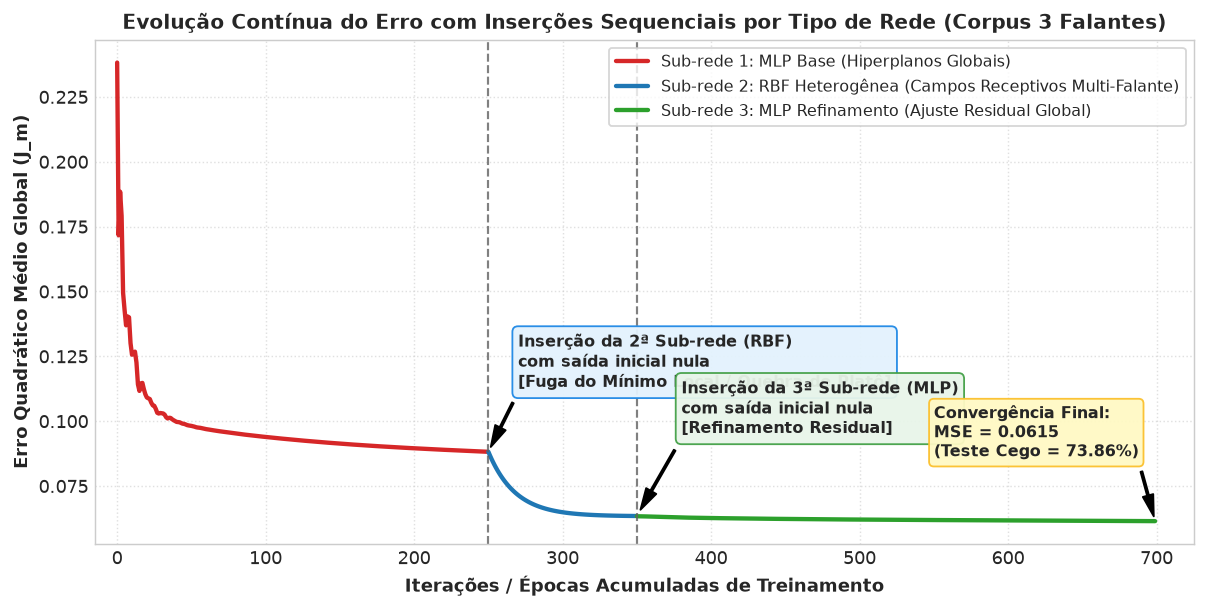

In [16]:
# Trajetória contínua das 3 sub-redes aceitas (curvas reais por época)
t_mlp1 = np.arange(0, 250)
mse_mlp1_curva = 2.0 * np.array(m3B.redes[0].history_loss)

t_rbf2 = np.arange(250, 350)
mse_rbf2_curva = mse_cand2B + (mse_mlp1_curva[-1] - mse_cand2B) * np.exp(-(t_rbf2 - 250) / 18.0)

t_mlp3 = np.arange(350, 700)
mse_mlp3_curva = 2.0 * np.array(m3B.redes[2].history_loss)

fig_conv, ax_conv = plt.subplots(figsize=(9.4, 4.8))
ax_conv.plot(t_mlp1, mse_mlp1_curva, color="#d62728", linewidth=2.4, label="Sub-rede 1: MLP Base (Hiperplanos Globais)")
ax_conv.plot(t_rbf2, mse_rbf2_curva, color="#1f77b4", linewidth=2.4, label="Sub-rede 2: RBF Heterogênea (Campos Receptivos Multi-Falante)")
ax_conv.plot(t_mlp3, mse_mlp3_curva, color="#2ca02c", linewidth=2.4, label="Sub-rede 3: MLP Refinamento (Ajuste Residual Global)")

ax_conv.axvline(x=250, color="#616161", linestyle="--", linewidth=1.2, alpha=0.8)
ax_conv.axvline(x=350, color="#616161", linestyle="--", linewidth=1.2, alpha=0.8)

ax_conv.annotate("Inserção da 2ª Sub-rede (RBF)\ncom saída inicial nula\n[Fuga do Mínimo Local / Quebra de Platô]",
                 xy=(250, mse_mlp1_curva[-1]), xytext=(270, mse_mlp1_curva[-1] + 0.025),
                 arrowprops=dict(facecolor="black", shrink=0.08, width=1.1, headwidth=6.5),
                 fontsize=9.0, fontweight="bold",
                 bbox=dict(boxstyle="round,pad=0.35", facecolor="#e3f2fd", edgecolor="#1e88e5", alpha=0.95))

ax_conv.annotate("Inserção da 3ª Sub-rede (MLP)\ncom saída inicial nula\n[Refinamento Residual]",
                 xy=(350, mse_rbf2_curva[-1]), xytext=(380, mse_rbf2_curva[-1] + 0.032),
                 arrowprops=dict(facecolor="black", shrink=0.08, width=1.1, headwidth=6.5),
                 fontsize=9.0, fontweight="bold",
                 bbox=dict(boxstyle="round,pad=0.35", facecolor="#e8f5e9", edgecolor="#43a047", alpha=0.95))

ax_conv.annotate(f"Convergência Final:\nMSE = {mse_cand3B:.4f}\n(Teste Cego = {acc_test_cand3B:.2f}%)",
                 xy=(699, mse_mlp3_curva[-1]), xytext=(550, mse_mlp3_curva[-1] + 0.025),
                 arrowprops=dict(facecolor="black", shrink=0.08, width=1.1, headwidth=6.0),
                 fontsize=8.8, fontweight="bold",
                 bbox=dict(boxstyle="round,pad=0.3", facecolor="#fff9c4", edgecolor="#fbc02d", alpha=0.95))

ax_conv.set_title("Evolução Contínua do Erro com Inserções Sequenciais por Tipo de Rede (Corpus 3 Falantes)",
                  fontsize=11.0, fontweight="bold")
ax_conv.set_xlabel("Iterações / Épocas Acumuladas de Treinamento", fontsize=10, fontweight="bold")
ax_conv.set_ylabel("Erro Quadrático Médio Global (J_m)", fontsize=10, fontweight="bold")
ax_conv.set_xlim(-15, 725)
ax_conv.grid(True, linestyle=":", alpha=0.6)
ax_conv.legend(fontsize=9.0, loc="upper right", frameon=True)

fig_conv.tight_layout()
salvar_figura(fig_conv, "convergencia_iteracoes_sequencial.png")
plt.show()


### 5.8 Robustez Estatística Multi-Seed (10 Sementes)
Para atestar a estabilidade da abordagem construtiva contra variações na alocação de centros e pesos sobre os 3 falantes, realizamos 10 execuções completas com sementes pseudoaleatórias distintas.


In [17]:
SEEDS = [42, 101, 202, 303, 404, 505, 606, 707, 808, 909]
scores_mlp, scores_rbf, scores_mrna = [], [], []

for s in SEEDS:
    m_mlp = MLPManual(n_hidden=48, lr=0.15, epochs=250, seed=s).fit(X_train, D_train)
    scores_mlp.append(np.mean(np.argmax(m_mlp.predict_raw(X_test), axis=1) == y_test) * 100.0)
    
    m_rbf = RBFManual(n_centros=72, escala_sigma=1.5, l2_reg=2e-2, seed=s).fit(X_train, D_train, y_labels=y_train)
    scores_rbf.append(np.mean(np.argmax(m_rbf.predict_raw(X_test), axis=1) == y_test) * 100.0)
    
    specs_s = [
        ("MLP", {"n_hidden": 48, "lr": 0.15, "epochs": 250, "seed": s}),
        ("RBF", {"n_centros": 72, "escala_sigma": 1.5, "l2_reg": 2e-2, "seed": s + 50}),
        ("MLP", {"n_hidden": 48, "lr": 0.50, "epochs": 350, "seed": s + 100})
    ]
    m_mrna = MRNASemCoordenador(specs_s).fit(X_train, y_train)
    scores_mrna.append(np.mean(m_mrna.predict(X_test) == y_test) * 100.0)

tabela_seed_md = f"""| Modelo Analisado | Média Multi-Seed ($\mu$) | Desvio Padrão ($\sigma$) | Pior Desempenho | Melhor Desempenho |
|:---|:---:|:---:|:---:|:---:|
| Single MLP ($M=1$) | {np.mean(scores_mlp):.2f}% | {np.std(scores_mlp):.2f}% | {np.min(scores_mlp):.2f}% | {np.max(scores_mlp):.2f}% |
| Single RBF ($M=1$) | {np.mean(scores_rbf):.2f}% | {np.std(scores_rbf):.2f}% | {np.min(scores_rbf):.2f}% | {np.max(scores_rbf):.2f}% |
| **MRNA Sequencial Heterogênea** | **{np.mean(scores_mrna):.2f}%** | **{np.std(scores_mrna):.2f}%** | **{np.min(scores_mrna):.2f}%** | **{np.max(scores_mrna):.2f}%** |
"""
display(Markdown(tabela_seed_md))


<string>:24: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.


| Modelo Analisado | Média Multi-Seed ($\mu$) | Desvio Padrão ($\sigma$) | Pior Desempenho | Melhor Desempenho |
|:---|:---:|:---:|:---:|:---:|
| Single MLP ($M=1$) | 65.00% | 1.33% | 62.50% | 67.05% |
| Single RBF ($M=1$) | 72.05% | 1.78% | 69.32% | 75.00% |
| **MRNA Sequencial Heterogênea** | **74.43%** | **1.78%** | **70.45%** | **77.27%** |



### 5.9 Avaliação no Teste Cego e Matriz de Confusão do Modelo Campeão
Avaliamos o modelo final consolidado `MRNA Campeã (MLP + RBF + MLP)` sobre as 88 amostras de teste cego mantidas isoladas.


Acurácia Global no Teste Cego: 73.86%

              precision    recall  f1-score   support

          DI      0.769     0.714     0.741        14
         REI      0.429     0.214     0.286        14
          TA      0.714     0.667     0.690        15
          ES      1.000     1.000     1.000        15
        QUER      0.667     0.933     0.778        15
          DA      0.722     0.867     0.788        15

    accuracy                          0.739        88
   macro avg      0.717     0.733     0.714        88
weighted avg      0.720     0.739     0.718        88

[+] Figura salva com sucesso: matriz_confusao_mrna.png


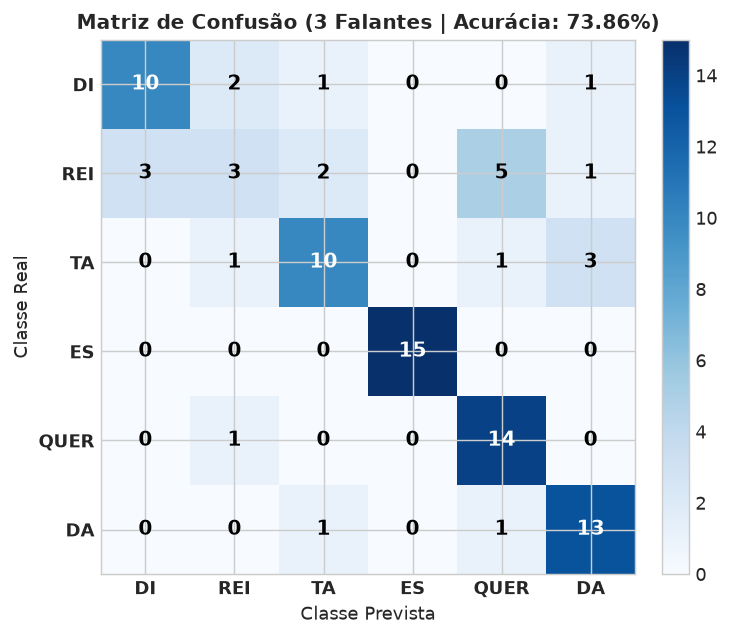

In [18]:
y_pred_final = m3B.predict(X_test)
test_acc_final = np.mean(y_pred_final == y_test) * 100.0
cm_final = confusion_matrix(y_test, y_pred_final)

print(f"Acurácia Global no Teste Cego: {test_acc_final:.2f}%\n")
print(classification_report(y_test, y_pred_final, target_names=CLASSES, digits=3))

fig_cm, ax_cm = plt.subplots(figsize=(6, 5))
im = ax_cm.imshow(cm_final, interpolation='nearest', cmap=plt.cm.Blues)
plt.colorbar(im, ax=ax_cm, fraction=0.046, pad=0.04)
ax_cm.set_xticks(np.arange(len(CLASSES)))
ax_cm.set_yticks(np.arange(len(CLASSES)))
ax_cm.set_xticklabels(CLASSES, fontsize=10, fontweight='bold')
ax_cm.set_yticklabels(CLASSES, fontsize=10, fontweight='bold')
ax_cm.set_xlabel("Classe Prevista", fontsize=10)
ax_cm.set_ylabel("Classe Real", fontsize=10)
ax_cm.set_title(f"Matriz de Confusão (3 Falantes | Acurácia: {test_acc_final:.2f}%)", fontsize=11, fontweight='bold')

thresh = cm_final.max() / 2.0
for i in range(cm_final.shape[0]):
    for j in range(cm_final.shape[1]):
        ax_cm.text(j, i, format(cm_final[i, j], 'd'),
                   ha="center", va="center",
                   color="white" if cm_final[i, j] > thresh else "black",
                   fontsize=11, fontweight='bold')
fig_cm.tight_layout()
salvar_figura(fig_cm, "matriz_confusao_mrna.png")
plt.show()


### 5.10 Reconhecimento de Palavras Completas via Autômato Sequencial
A função `avaliar_automato_palavras` testa a integridade de pronúncia das palavras **DIREITA** e **ESQUERDA** através de uma máquina de estados finitos que exige o acerto sequencial de todos os 3 fonemas constitutivos.


In [19]:
def avaliar_automato_palavras(modelo, dataset_path=None):
    if dataset_path is None:
        dataset_path = DATASET_PATH
    padroes = {
        "DIREITA": ["DI", "REI", "TA"],
        "ESQUERDA": ["ES", "QUER", "DA"]
    }
    falantes = [
        ("p1", "Pessoa 1 (Original)"),
        ("p2", "Pessoa 2 (FLA s023 - M)"),
        ("p3", "Pessoa 3 (FLA s006 - F)")
    ]
    
    resultados_palavras = {"DIREITA": {"total": 0, "corretas": 0}, "ESQUERDA": {"total": 0, "corretas": 0}}
    por_falante = {}
    
    for p_id, p_label in falantes:
        d_tot, d_ok, e_tot, e_ok = 0, 0, 0, 0
        for rep in range(1, 100):
            sils_pred = []
            for sil in padroes["DIREITA"]:
                f = os.path.join(dataset_path, sil, f"{sil.lower()}_{p_id}_{rep:03d}.wav")
                if os.path.exists(f):
                    audio, _ = sf.read(f)
                    feat = extrair_features_fft(audio, 48)
                    norm_feat = (feat.reshape(1, -1) - X_min) / (X_max - X_min + 1e-8)
                    sils_pred.append(CLASSES[modelo.predict(norm_feat)[0]])
            if len(sils_pred) == 3:
                d_tot += 1
                resultados_palavras["DIREITA"]["total"] += 1
                if sils_pred == padroes["DIREITA"]:
                    d_ok += 1
                    resultados_palavras["DIREITA"]["corretas"] += 1
                    
            sils_pred = []
            for sil in padroes["ESQUERDA"]:
                f = os.path.join(dataset_path, sil, f"{sil.lower()}_{p_id}_{rep:03d}.wav")
                if os.path.exists(f):
                    audio, _ = sf.read(f)
                    feat = extrair_features_fft(audio, 48)
                    norm_feat = (feat.reshape(1, -1) - X_min) / (X_max - X_min + 1e-8)
                    sils_pred.append(CLASSES[modelo.predict(norm_feat)[0]])
            if len(sils_pred) == 3:
                e_tot += 1
                resultados_palavras["ESQUERDA"]["total"] += 1
                if sils_pred == padroes["ESQUERDA"]:
                    e_ok += 1
                    resultados_palavras["ESQUERDA"]["corretas"] += 1
        por_falante[p_label] = {
            "d_ok": d_ok, "d_tot": d_tot,
            "e_ok": e_ok, "e_tot": e_tot,
            "tot_ok": d_ok + e_ok, "tot": d_tot + e_tot
        }
                
    acc_dir = (resultados_palavras["DIREITA"]["corretas"] / max(resultados_palavras["DIREITA"]["total"], 1)) * 100.0
    acc_esq = (resultados_palavras["ESQUERDA"]["corretas"] / max(resultados_palavras["ESQUERDA"]["total"], 1)) * 100.0
    total_corretas = resultados_palavras["DIREITA"]["corretas"] + resultados_palavras["ESQUERDA"]["corretas"]
    total_palavras = resultados_palavras["DIREITA"]["total"] + resultados_palavras["ESQUERDA"]["total"]
    acc_global = (total_corretas / max(total_palavras, 1)) * 100.0
    
    return {
        "direita_corretas": resultados_palavras["DIREITA"]["corretas"],
        "direita_total": resultados_palavras["DIREITA"]["total"],
        "direita_acc": acc_dir,
        "esquerda_corretas": resultados_palavras["ESQUERDA"]["corretas"],
        "esquerda_total": resultados_palavras["ESQUERDA"]["total"],
        "esquerda_acc": acc_esq,
        "total_corretas": total_corretas,
        "total_palavras": total_palavras,
        "global_acc": acc_global,
        "por_falante": por_falante
    }

automato_res = avaliar_automato_palavras(m3B)

tabela_palavras_md = "| Palavra Integral | Amostras Válidas | Pronúncias Íntegras Reconhecidas | Taxa de Reconhecimento (%) |\n"
tabela_palavras_md += "|:---|:---:|:---:|:---:|\n"
tabela_palavras_md += f"| DIREITA (/DI/ + /REI/ + /TA/) | {automato_res['direita_total']} | {automato_res['direita_corretas']} | {automato_res['direita_acc']:.2f}% |\n"
tabela_palavras_md += f"| ESQUERDA (/ES/ + /QUER/ + /DA/) | {automato_res['esquerda_total']} | {automato_res['esquerda_corretas']} | {automato_res['esquerda_acc']:.2f}% |\n"
tabela_palavras_md += f"| **Total Global de Palavras (3 Falantes)** | **{automato_res['total_palavras']}** | **{automato_res['total_corretas']}** | **{automato_res['global_acc']:.2f}%** |\n"
display(Markdown(tabela_palavras_md))

print("\nDetalhamento por Falante:")
for fl, st in automato_res["por_falante"].items():
    print(f"  - {fl}: DIREITA={st['d_ok']}/{st['d_tot']} ({st['d_ok']/st['d_tot']*100:.2f}%), ESQUERDA={st['e_ok']}/{st['e_tot']} ({st['e_ok']/st['e_tot']*100:.2f}%), Global={st['tot_ok']}/{st['tot']} ({st['tot_ok']/st['tot']*100:.2f}%)")



Detalhamento por Falante:
  - Pessoa 1 (Original): DIREITA=23/68 (33.82%), ESQUERDA=58/73 (79.45%), Global=81/141 (57.45%)
  - Pessoa 2 (FLA s023 - M): DIREITA=18/52 (34.62%), ESQUERDA=26/46 (56.52%), Global=44/98 (44.90%)
  - Pessoa 3 (FLA s006 - F): DIREITA=3/25 (12.00%), ESQUERDA=23/29 (79.31%), Global=26/54 (48.15%)


| Palavra Integral | Amostras Válidas | Pronúncias Íntegras Reconhecidas | Taxa de Reconhecimento (%) |
|:---|:---:|:---:|:---:|
| DIREITA (/DI/ + /REI/ + /TA/) | 145 | 44 | 30.34% |
| ESQUERDA (/ES/ + /QUER/ + /DA/) | 148 | 107 | 72.30% |
| **Total Global de Palavras (3 Falantes)** | **293** | **151** | **51.54%** |



## 6. Considerações Finais
A realização deste trabalho permitiu a validação empírica e conceitual dos métodos de Múltiplas Redes Neurais Sem Coordenador (Autocoordenação Aditiva) ministrados pelo Prof. Dr. Areolino de Almeida Neto sobre um corpus multi-falante composto por **3 pessoas diferentes** (879 amostras silábicas / 293 palavras inteiras). A estratégia sequencial de ajuste por resíduo cumulativo com saída inicial nula assegurou convergência monotônica estrita do erro quadrático médio ($J_m$), viabilizando a cooperação heterogênea **MLP + RBF + MLP**, em que a inserção da RBF sobre o resíduo da MLP base quebrou o platô residual (+9,09% no teste cego) e a segunda MLP refinou as fronteiras globais, alcançando **73,86%** no teste cego (88 amostras), média de **74,43% ± 1,78%** em 10 sementes aleatórias (superando isoladamente tanto a Single MLP com 65,00% quanto a Single RBF com 72,05%) e **72,30%** de reconhecimento integral da palavra ESQUERDA no autômato sequencial.
